## Part 1 – Load and understand the dataset

Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# For feature selection
from sklearn.feature_selection import mutual_info_classif

# Display all columns
pd.set_option('display.max_columns', None)

Load the Dataset

In [2]:
# Load Excel file
df = pd.read_excel("Delinquency_prediction_dataset.xlsx")

# Display first five rows
print(df.head())

# Dataset dimensions
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

  Customer_ID  Age    Income  Credit_Score  Credit_Utilization  \
0    CUST0001   56  165580.0         398.0            0.390502   
1    CUST0002   69  100999.0         493.0            0.312444   
2    CUST0003   46  188416.0         500.0            0.359930   
3    CUST0004   32  101672.0         413.0            0.371400   
4    CUST0005   60   38524.0         487.0            0.234716   

   Missed_Payments  Delinquent_Account  Loan_Balance  Debt_to_Income_Ratio  \
0                3                   0       16310.0              0.317396   
1                6                   1       17401.0              0.196093   
2                0                   0       13761.0              0.301655   
3                3                   0       88778.0              0.264794   
4                2                   0       13316.0              0.510583   

  Employment_Status  Account_Tenure Credit_Card_Type     Location Month_1  \
0               EMP              18          Student  Los

Understand columns and data types

In [3]:
# Information about dataset
df.info()

# Statistical summary of numerical columns
print(df.describe())

# Identify categorical columns
categorical_cols = df.select_dtypes(include='object').columns

# Identify numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns

print("\nCategorical Columns:")
print(list(categorical_cols))

print("\nNumerical Columns:")
print(list(numerical_cols))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           500 non-null    object 
 1   Age                   500 non-null    int64  
 2   Income                461 non-null    float64
 3   Credit_Score          498 non-null    float64
 4   Credit_Utilization    500 non-null    float64
 5   Missed_Payments       500 non-null    int64  
 6   Delinquent_Account    500 non-null    int64  
 7   Loan_Balance          471 non-null    float64
 8   Debt_to_Income_Ratio  500 non-null    float64
 9   Employment_Status     500 non-null    object 
 10  Account_Tenure        500 non-null    int64  
 11  Credit_Card_Type      500 non-null    object 
 12  Location              500 non-null    object 
 13  Month_1               500 non-null    object 
 14  Month_2               500 non-null    object 
 15  Month_3               5

Identify key variables

In [4]:
key_variables = {
    "Age": "Customer's age",
    "Income": "Customer's annual income",
    "Credit_Score": "Customer's credit score",
    "Credit_Utilization": "Percentage of available credit being used",
    "Missed_Payments": "Number of previously missed payments",
    "Loan_Balance": "Outstanding loan balance",
    "Debt_to_Income_Ratio": "Debt compared to income",
    "Employment_Status": "Customer's employment category",
    "Account_Tenure": "Duration of customer relationship",
    "Delinquent_Account": "Target variable (0 = No, 1 = Yes)"
}

for column, description in key_variables.items():
    print(column, ":", description)

Age : Customer's age
Income : Customer's annual income
Credit_Score : Customer's credit score
Credit_Utilization : Percentage of available credit being used
Missed_Payments : Number of previously missed payments
Loan_Balance : Outstanding loan balance
Debt_to_Income_Ratio : Debt compared to income
Employment_Status : Customer's employment category
Account_Tenure : Duration of customer relationship
Delinquent_Account : Target variable (0 = No, 1 = Yes)


## Part 2 – Exploratory Data Analysis (EDA)

Check missing values

In [5]:
# Count missing values
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (missing_values / len(df)) * 100

# Create summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

# Show only columns containing missing values
print(missing_summary[missing_summary["Missing Values"] > 0])

              Missing Values  Percentage
Income                    39         7.8
Credit_Score               2         0.4
Loan_Balance              29         5.8


Check duplicate records

In [6]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Customer IDs: 0


Check inconsistent categorical values

In [7]:
# Check unique employment categories
print(df["Employment_Status"].value_counts())

# Check unique credit card categories
print(df["Credit_Card_Type"].value_counts())

# Check payment history categories
for col in ["Month_1", "Month_2", "Month_3",
            "Month_4", "Month_5", "Month_6"]:

    print(f"\n{col}:")
    print(df[col].value_counts())

Employment_Status
Unemployed       93
retired          87
Employed         82
EMP              81
Self-employed    80
employed         77
Name: count, dtype: int64
Credit_Card_Type
Gold        118
Student     112
Business    108
Standard     86
Platinum     76
Name: count, dtype: int64

Month_1:
Month_1
On-time    177
Missed     164
Late       159
Name: count, dtype: int64

Month_2:
Month_2
Late       173
Missed     167
On-time    160
Name: count, dtype: int64

Month_3:
Month_3
Late       169
On-time    169
Missed     162
Name: count, dtype: int64

Month_4:
Month_4
Late       181
Missed     160
On-time    159
Name: count, dtype: int64

Month_5:
Month_5
Missed     187
On-time    162
Late       151
Name: count, dtype: int64

Month_6:
Month_6
Late       172
Missed     168
On-time    160
Name: count, dtype: int64


Visualize delinquency distribution

Delinquent_Account
0    420
1     80
Name: count, dtype: int64


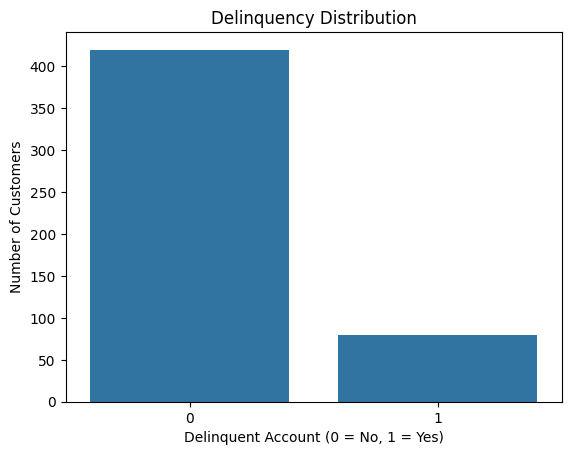

In [8]:
# Count target classes
print(df["Delinquent_Account"].value_counts())

# Plot distribution
sns.countplot(data=df, x="Delinquent_Account")

plt.title("Delinquency Distribution")
plt.xlabel("Delinquent Account (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

Analyze numerical distributions

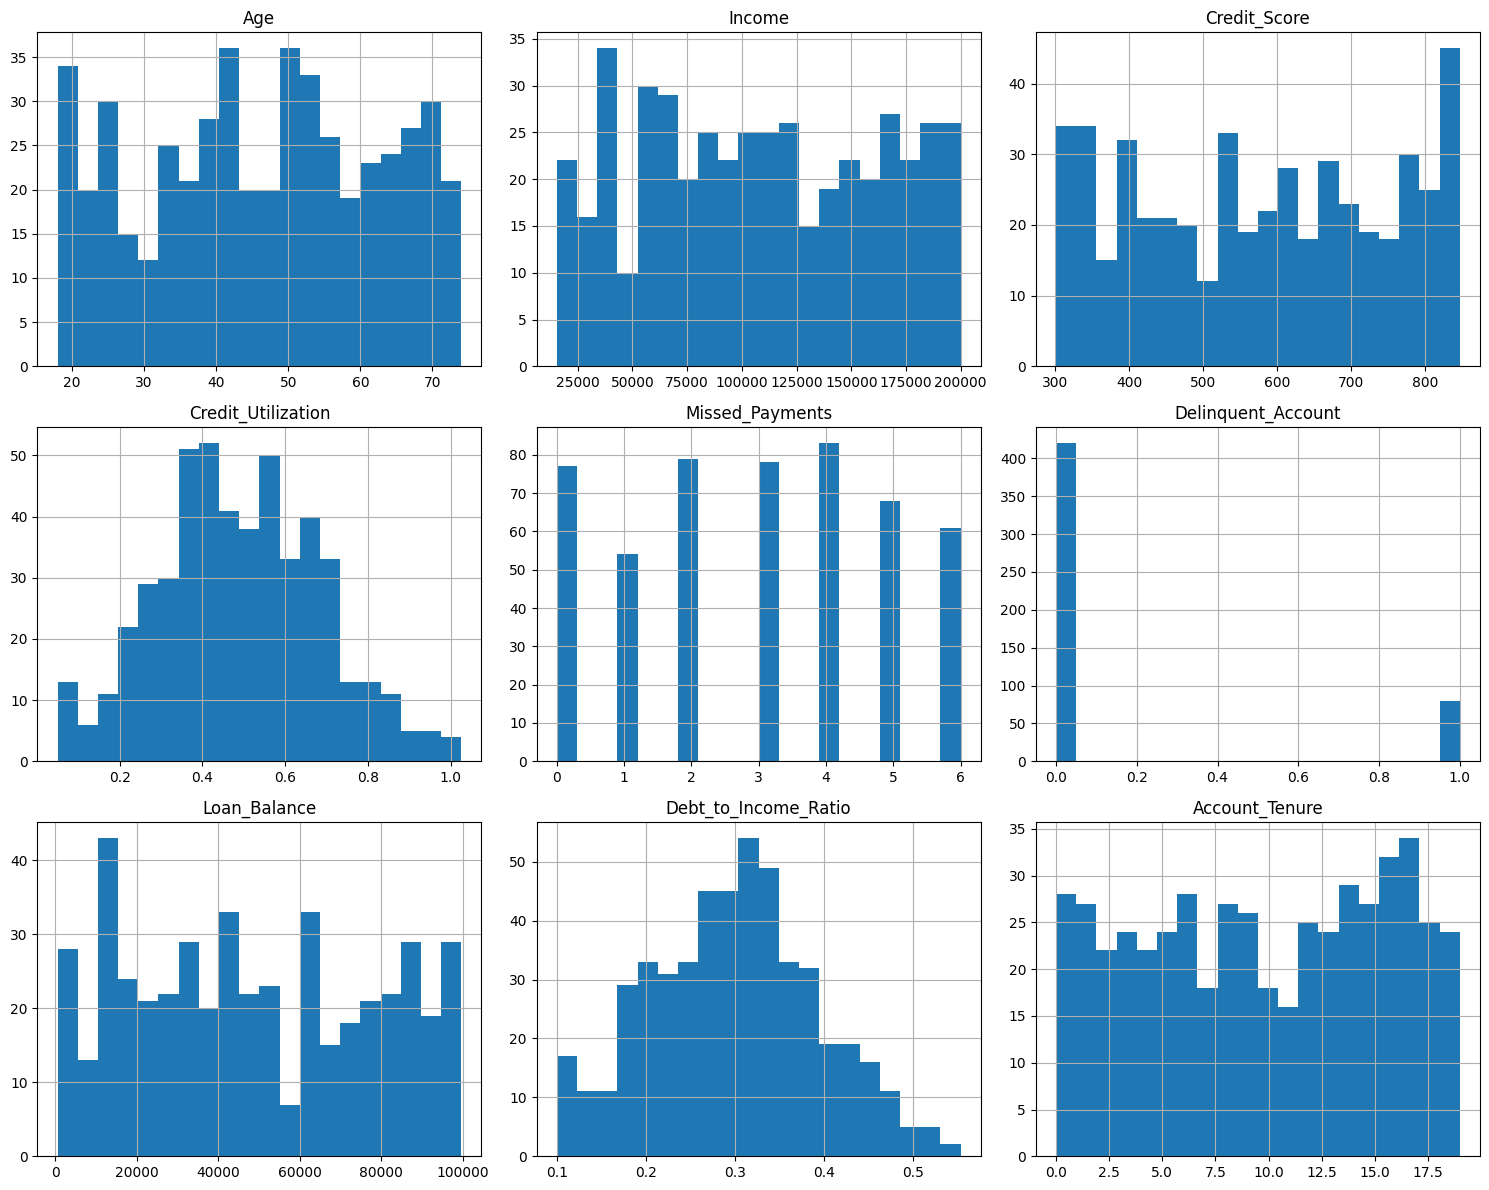

In [9]:
# Plot histograms for numerical variables
df[numerical_cols].hist(figsize=(15, 12), bins=20)

plt.tight_layout()
plt.show()

Detect outliers using IQR

In [10]:
# Select numerical columns except target
numeric_features = df.select_dtypes(include=np.number).drop(
    columns=["Delinquent_Account"]
)

for col in numeric_features.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(col, ":", len(outliers), "potential outliers")

Age : 0 potential outliers
Income : 0 potential outliers
Credit_Score : 0 potential outliers
Credit_Utilization : 0 potential outliers
Missed_Payments : 0 potential outliers
Loan_Balance : 0 potential outliers
Debt_to_Income_Ratio : 0 potential outliers
Account_Tenure : 0 potential outliers


Check credit utilization above 100%

In [11]:
high_utilization = df[df["Credit_Utilization"] > 1]

print("Customers with utilization above 100%:",
      len(high_utilization))

print(high_utilization[
    ["Customer_ID", "Credit_Utilization"]
])

Customers with utilization above 100%: 4
    Customer_ID  Credit_Utilization
89     CUST0090            1.025843
265    CUST0266            1.025017
292    CUST0293            1.002482
426    CUST0427            1.008734


Analyze financial variables against delinquency

In [12]:
financial_columns = [
    "Income",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Age",
    "Account_Tenure"
]

# Compare averages for delinquent and non-delinquent customers
comparison = df.groupby("Delinquent_Account")[
    financial_columns
].mean()

print(comparison.T)

# Correlation with target
correlations = df[financial_columns + [
    "Delinquent_Account"
]].corr(numeric_only=True)

print("\nCorrelation with delinquency:")
print(correlations["Delinquent_Account"].sort_values(ascending=False))

Delinquent_Account                0              1
Income                107306.943005  113902.013333
Credit_Score             575.145933     591.150000
Credit_Utilization         0.488505       0.506887
Missed_Payments            2.990476       2.850000
Loan_Balance           48708.756281   48358.232877
Debt_to_Income_Ratio       0.297445       0.306301
Age                       46.107143      47.100000
Account_Tenure             9.842857       9.200000

Correlation with delinquency:
Delinquent_Account      1.000000
Income                  0.045409
Credit_Score            0.034833
Debt_to_Income_Ratio    0.034386
Credit_Utilization      0.034224
Age                     0.022508
Loan_Balance           -0.004320
Missed_Payments        -0.026478
Account_Tenure         -0.039829
Name: Delinquent_Account, dtype: float64


## Part 3 – Identify the top predictive variables

Feature importance using Mutual Information

In [13]:
target = df["Delinquent_Account"]

results = []

# Exclude ID and target
features = df.drop(
    columns=["Customer_ID", "Delinquent_Account"]
)

for col in features.columns:

    if features[col].dtype == "object":

        # Convert categorical values into numerical codes
        values = features[col].fillna("Unknown").astype(str)
        encoded = pd.factorize(values)[0]

        score = mutual_info_classif(
            encoded.reshape(-1, 1),
            target,
            discrete_features=True,
            random_state=42
        )[0]

    else:

        # Fill missing values temporarily for analysis
        values = features[col].fillna(
            features[col].median()
        )

        score = mutual_info_classif(
            values.to_frame(),
            target,
            discrete_features=False,
            random_state=42
        )[0]

    results.append((col, score))

# Create ranking
mi_results = pd.DataFrame(
    results,
    columns=["Variable", "Mutual_Information"]
)

mi_results = mi_results.sort_values(
    by="Mutual_Information",
    ascending=False
)

print(mi_results)

# Display top 3
print("\nTop 3 Predictive Candidates:")
print(mi_results.head(3))

                Variable  Mutual_Information
8         Account_Tenure            0.027159
4        Missed_Payments            0.025148
11               Month_1            0.004628
9       Credit_Card_Type            0.004346
14               Month_4            0.004346
7      Employment_Status            0.002580
10              Location            0.002428
15               Month_5            0.002108
6   Debt_to_Income_Ratio            0.001956
16               Month_6            0.001501
12               Month_2            0.000408
13               Month_3            0.000382
0                    Age            0.000000
5           Loan_Balance            0.000000
1                 Income            0.000000
2           Credit_Score            0.000000
3     Credit_Utilization            0.000000

Top 3 Predictive Candidates:
           Variable  Mutual_Information
8    Account_Tenure            0.027159
4   Missed_Payments            0.025148
11          Month_1            0.004628


Higher mutual information means a variable contains more information about the target individually. It does not prove that the variable will be useful in a combined predictive model.

## Part 4 – Data cleaning and imputation

Create a working copy

In [14]:
# Create a separate copy
df_clean = df.copy()

Standardize Employment_Status

In [15]:
df_clean["Employment_Status"] = (
    df_clean["Employment_Status"]
    .str.strip()
    .str.lower()
)

# Replace inconsistent categories
df_clean["Employment_Status"] = (
    df_clean["Employment_Status"].replace({
        "emp": "employed"
    })
)

print(df_clean["Employment_Status"].value_counts())

Employment_Status
employed         240
unemployed        93
retired           87
self-employed     80
Name: count, dtype: int64


Impute missing Loan_Balance using median

In [16]:
loan_median = df_clean["Loan_Balance"].median()

df_clean["Loan_Balance_Imputed"] = (
    df_clean["Loan_Balance"].isnull().astype(int)
)

df_clean["Loan_Balance"] = (
    df_clean["Loan_Balance"].fillna(loan_median)
)

print("Missing Loan Balance:",
      df_clean["Loan_Balance"].isnull().sum())

print("Median used:", loan_median)

Missing Loan Balance: 0
Median used: 45776.0


Impute missing Credit_Score using median

In [17]:
credit_median = df_clean["Credit_Score"].median()

df_clean["Credit_Score_Imputed"] = (
    df_clean["Credit_Score"].isnull().astype(int)
)

df_clean["Credit_Score"] = (
    df_clean["Credit_Score"].fillna(credit_median)
)

print("Missing Credit Score:",
      df_clean["Credit_Score"].isnull().sum())

print("Median used:", credit_median)

Missing Credit Score: 0
Median used: 586.0


Generate synthetic Income values using normal distribution

We will:
1. Calculate mean and standard deviation from available income values.
2. Generate random values using a normal distribution.
3. Restrict generated values to the observed minimum and maximum.
4. Replace missing income entries.

In [18]:
# Calculate statistical parameters
income_mean = df_clean["Income"].mean()
income_std = df_clean["Income"].std()

income_min = df_clean["Income"].min()
income_max = df_clean["Income"].max()

print("Income Mean:", income_mean)
print("Income Standard Deviation:", income_std)
print("Income Minimum:", income_min)
print("Income Maximum:", income_max)

# Identify missing income rows
missing_income = df_clean["Income"].isnull()

# Count missing values
missing_count = missing_income.sum()

# Generate reproducible random values
np.random.seed(42)

synthetic_income = np.random.normal(
    loc=income_mean,
    scale=income_std,
    size=missing_count
)

# Keep values within observed range
synthetic_income = np.clip(
    synthetic_income,
    income_min,
    income_max
)

# Add missingness indicator
df_clean["Income_Imputed"] = missing_income.astype(int)

# Replace missing values
df_clean.loc[missing_income, "Income"] = synthetic_income

print("\nGenerated Income Values:")
print(df_clean.loc[missing_income, [
    "Customer_ID", "Income"
]])

print("\nRemaining Missing Income:",
      df_clean["Income"].isnull().sum())

Income Mean: 108379.89370932755
Income Standard Deviation: 53662.72374117145
Income Minimum: 15404.0
Income Maximum: 199943.0

Generated Income Values:
    Customer_ID         Income
40     CUST0041  135034.928081
42     CUST0043  100960.254712
59     CUST0060  143136.624800
66     CUST0067  190109.824143
68     CUST0069   95814.585848
76     CUST0077   95815.466871
93     CUST0094  193124.754756
113    CUST0114  149562.531569
144    CUST0145   83186.619433
153    CUST0154  137495.143441
187    CUST0188   83511.638083
208    CUST0209   83387.566605
224    CUST0225  121364.248244
228    CUST0229   15404.000000
272    CUST0273   15816.104587
276    CUST0277   78206.013365
278    CUST0279   54028.617102
290    CUST0291  125243.261505
293    CUST0294   59652.848594
298    CUST0299   32591.830346
299    CUST0300  187030.598698
307    CUST0308   96264.122469
369    CUST0370  112003.641102
370    CUST0371   31924.025392
375    CUST0376   79166.833954
376    CUST0377  114332.301998
378    CUST

This implements the requested normal-distribution assumption. It is a simple synthetic imputation method, not a guarantee that each generated income represents the actual customer's income.

Visualize income before and after imputation

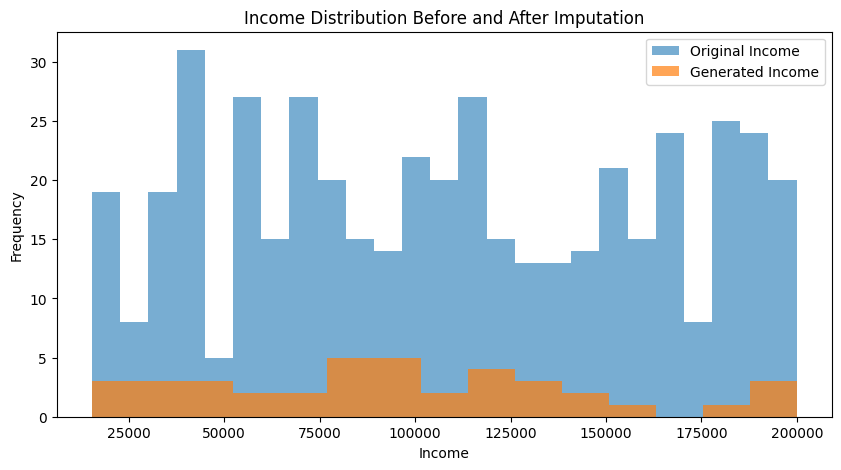

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["Income"].dropna(),
    bins=25,
    alpha=0.6,
    label="Original Income"
)

plt.hist(
    df_clean.loc[df_clean["Income_Imputed"] == 1, "Income"],
    bins=15,
    alpha=0.7,
    label="Generated Income"
)

plt.title("Income Distribution Before and After Imputation")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.legend()

plt.show()

## Part 5 – Credit Utilization missing-value handling

Current dataset has zero missing values in Credit_Utilization. However, we'll prepare a method for future missing entries.

Group-based median imputation

We'll use Credit_Card_Type to estimate missing utilization values.

In [20]:
# Create missingness indicator
df_clean["Utilization_Imputed"] = (
    df_clean["Credit_Utilization"].isnull().astype(int)
)

# Calculate overall median
overall_median = df_clean["Credit_Utilization"].median()

# Calculate median by credit card type
group_median = df_clean.groupby(
    "Credit_Card_Type"
)["Credit_Utilization"].transform("median")

# Fill missing values using group median
df_clean["Credit_Utilization"] = (
    df_clean["Credit_Utilization"]
    .fillna(group_median)
    .fillna(overall_median)
)

print("Remaining missing utilization:",
      df_clean["Credit_Utilization"].isnull().sum())

print("Values imputed:",
      df_clean["Utilization_Imputed"].sum())

Remaining missing utilization: 0
Values imputed: 0


Why this method? Customers with similar credit card types may have more comparable utilization patterns than the entire customer population.

## Part 6 – Additional feature engineering

Monthly payment history can provide useful information about repayment behavior.

Create payment history features

We'll count how many times each customer made late, missed, or on-time payments across six months.

In [21]:
payment_columns = [
    "Month_1",
    "Month_2",
    "Month_3",
    "Month_4",
    "Month_5",
    "Month_6"
]

# Count payment categories
df_clean["Late_Payment_Count"] = (
    df_clean[payment_columns] == "Late"
).sum(axis=1)

df_clean["Missed_Payment_Count"] = (
    df_clean[payment_columns] == "Missed"
).sum(axis=1)

df_clean["On_Time_Payment_Count"] = (
    df_clean[payment_columns] == "On-time"
).sum(axis=1)

# Display results
print(df_clean[[
    "Customer_ID",
    "Late_Payment_Count",
    "Missed_Payment_Count",
    "On_Time_Payment_Count"
]].head())

  Customer_ID  Late_Payment_Count  Missed_Payment_Count  On_Time_Payment_Count
0    CUST0001                   4                     2                      0
1    CUST0002                   1                     3                      2
2    CUST0003                   3                     2                      1
3    CUST0004                   4                     2                      0
4    CUST0005                   3                     2                      1


Compare payment history with delinquency

                    Late_Payment_Count  Missed_Payment_Count  \
Delinquent_Account                                             
0                             2.021429              2.016667   
1                             1.950000              2.012500   

                    On_Time_Payment_Count  
Delinquent_Account                         
0                                1.961905  
1                                2.037500  


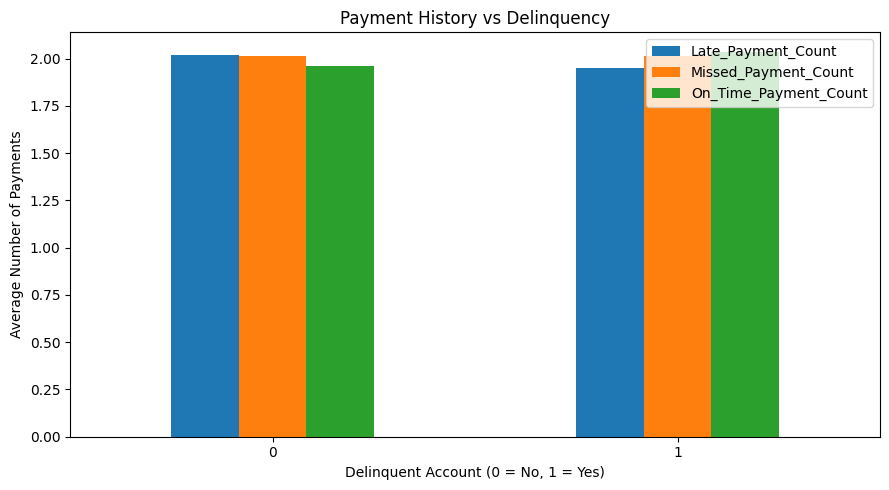

In [22]:
payment_comparison = df_clean.groupby(
    "Delinquent_Account"
)[[
    "Late_Payment_Count",
    "Missed_Payment_Count",
    "On_Time_Payment_Count"
]].mean()

print(payment_comparison)

payment_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Payment History vs Delinquency")
plt.xlabel("Delinquent Account (0 = No, 1 = Yes)")
plt.ylabel("Average Number of Payments")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

## Part 7 – Final verification

Check remaining missing values

In [23]:
print("Missing Values After Imputation:\n")

print(
    df_clean.isnull().sum()[
        df_clean.isnull().sum() > 0
    ]
)

print("\nFinal Dataset Shape:", df_clean.shape)

Missing Values After Imputation:

Series([], dtype: int64)

Final Dataset Shape: (500, 26)


Verify imputed records

In [24]:
print("Income Imputed:",
      df_clean["Income_Imputed"].sum())

print("Loan Balance Imputed:",
      df_clean["Loan_Balance_Imputed"].sum())

print("Credit Score Imputed:",
      df_clean["Credit_Score_Imputed"].sum())

print("Credit Utilization Imputed:",
      df_clean["Utilization_Imputed"].sum())

Income Imputed: 39
Loan Balance Imputed: 29
Credit Score Imputed: 2
Credit Utilization Imputed: 0


Compare delinquency rates across financial variables

In [25]:
# Select important numerical variables
risk_columns = [
    "Age",
    "Income",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Account_Tenure"
]

# Compare averages by delinquency status
risk_comparison = df_clean.groupby(
    "Delinquent_Account"
)[risk_columns].mean().T

risk_comparison.columns = [
    "Non_Delinquent",
    "Delinquent"
]

print(risk_comparison.round(2))

                      Non_Delinquent  Delinquent
Age                            46.11       47.10
Income                     106932.11   110157.96
Credit_Score                  575.20      591.15
Credit_Utilization              0.49        0.51
Missed_Payments                 2.99        2.85
Loan_Balance                48555.14    48132.29
Debt_to_Income_Ratio            0.30        0.31
Account_Tenure                  9.84        9.20


What to observe: Which variables have higher averages among delinquent customers?

Analyze credit utilization vs delinquency

In [26]:
# Create utilization groups
bins = [0, 0.25, 0.50, 0.75, 1.00, float("inf")]

labels = [
    "0-25%",
    "25-50%",
    "50-75%",
    "75-100%",
    "Above 100%"
]

df_clean["Utilization_Group"] = pd.cut(
    df_clean["Credit_Utilization"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate delinquency rate
utilization_analysis = df_clean.groupby(
    "Utilization_Group",
    observed=False
)["Delinquent_Account"].agg(
    ["count", "mean"]
)

utilization_analysis["Delinquency_Rate"] = (
    utilization_analysis["mean"] * 100
)

print(utilization_analysis.round(2))

                   count  mean  Delinquency_Rate
Utilization_Group                               
0-25%                 55  0.07              7.27
25-50%               210  0.18             17.62
50-75%               190  0.17             16.84
75-100%               41  0.17             17.07
Above 100%             4  0.00              0.00


Visualize utilization and delinquency

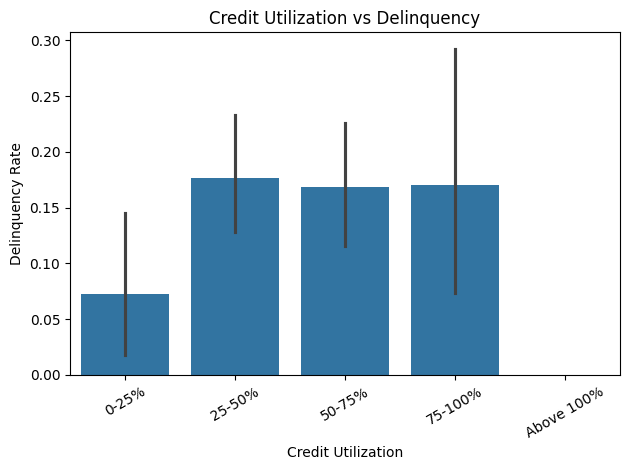

In [27]:
sns.barplot(
    data=df_clean,
    x="Utilization_Group",
    y="Delinquent_Account"
)

plt.title("Credit Utilization vs Delinquency")
plt.xlabel("Credit Utilization")
plt.ylabel("Delinquency Rate")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

What to observe: Does delinquency increase as credit utilization increases, or is the relationship inconsistent?

Analyze missed payments vs delinquency

In [28]:
missed_analysis = df_clean.groupby(
    "Missed_Payments"
)["Delinquent_Account"].agg(
    ["count", "mean"]
)

missed_analysis["Delinquency_Rate"] = (
    missed_analysis["mean"] * 100
)

print(missed_analysis.round(2))

                 count  mean  Delinquency_Rate
Missed_Payments                               
0                   77  0.18             18.18
1                   54  0.19             18.52
2                   79  0.16             16.46
3                   78  0.12             11.54
4                   83  0.14             14.46
5                   68  0.22             22.06
6                   61  0.11             11.48


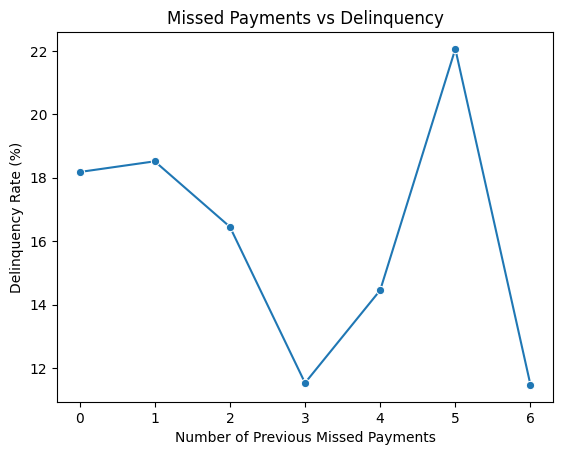

In [29]:
sns.lineplot(
    data=missed_analysis.reset_index(),
    x="Missed_Payments",
    y="Delinquency_Rate",
    marker="o"
)

plt.title("Missed Payments vs Delinquency")
plt.xlabel("Number of Previous Missed Payments")
plt.ylabel("Delinquency Rate (%)")

plt.show()

Analyze monthly payment history

In [30]:
payment_columns = [
    "Month_1",
    "Month_2",
    "Month_3",
    "Month_4",
    "Month_5",
    "Month_6"
]

# Standardize payment history
for col in payment_columns:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Count each payment category
df_clean["Missed_Months"] = (
    df_clean[payment_columns] == "missed"
).sum(axis=1)

df_clean["Late_Months"] = (
    df_clean[payment_columns] == "late"
).sum(axis=1)

df_clean["On_Time_Months"] = (
    df_clean[payment_columns] == "on-time"
).sum(axis=1)

# Compare payment behavior
payment_analysis = df_clean.groupby(
    "Delinquent_Account"
)[[
    "Missed_Months",
    "Late_Months",
    "On_Time_Months"
]].mean()

print(payment_analysis.round(2))

                    Missed_Months  Late_Months  On_Time_Months
Delinquent_Account                                            
0                            2.02         2.02            1.96
1                            2.01         1.95            2.04


Analyze individual monthly payment patterns

In [31]:
for col in payment_columns:

    print("\nAnalysis of", col)

    monthly_analysis = df_clean.groupby(
        col
    )["Delinquent_Account"].agg(
        ["count", "mean"]
    )

    monthly_analysis["Delinquency_Rate"] = (
        monthly_analysis["mean"] * 100
    )

    print(monthly_analysis.round(2))


Analysis of Month_1
         count  mean  Delinquency_Rate
Month_1                               
late       159  0.11             11.32
missed     164  0.16             16.46
on-time    177  0.20             19.77

Analysis of Month_2
         count  mean  Delinquency_Rate
Month_2                               
late       173  0.15             15.03
missed     167  0.16             15.57
on-time    160  0.18             17.50

Analysis of Month_3
         count  mean  Delinquency_Rate
Month_3                               
late       169  0.15             14.79
missed     162  0.17             17.28
on-time    169  0.16             15.98

Analysis of Month_4
         count  mean  Delinquency_Rate
Month_4                               
late       181  0.19             19.34
missed     160  0.17             16.88
on-time    159  0.11             11.32

Analysis of Month_5
         count  mean  Delinquency_Rate
Month_5                               
late       151  0.19             19.2

Analyze employment and credit card categories

In [32]:
categorical_features = [
    "Employment_Status",
    "Credit_Card_Type",
    "Location"
]

for col in categorical_features:

    print("\nDelinquency Analysis:", col)

    category_analysis = df_clean.groupby(
        col
    )["Delinquent_Account"].agg(
        ["count", "mean"]
    )

    category_analysis["Delinquency_Rate"] = (
        category_analysis["mean"] * 100
    )

    print(
        category_analysis.sort_values(
            "Delinquency_Rate",
            ascending=False
        ).round(2)
    )


Delinquency Analysis: Employment_Status
                   count  mean  Delinquency_Rate
Employment_Status                               
unemployed            93  0.19             19.35
employed             240  0.16             16.25
self-employed         80  0.16             16.25
retired               87  0.11             11.49

Delinquency Analysis: Credit_Card_Type
                  count  mean  Delinquency_Rate
Credit_Card_Type                               
Business            108  0.21             21.30
Student             112  0.18             17.86
Gold                118  0.14             14.41
Standard             86  0.13             12.79
Platinum             76  0.12             11.84

Delinquency Analysis: Location
             count  mean  Delinquency_Rate
Location                                  
Los Angeles    107  0.20             19.63
Houston         95  0.17             16.84
Phoenix        103  0.17             16.50
Chicago        103  0.15             14.56

Correlation analysis

Delinquent_Account      1.000000
Credit_Score            0.034733
Debt_to_Income_Ratio    0.034386
Credit_Utilization      0.034224
Age                     0.022508
Income                  0.022146
Loan_Balance           -0.005438
Missed_Payments        -0.026478
Account_Tenure         -0.039829
Name: Delinquent_Account, dtype: float64


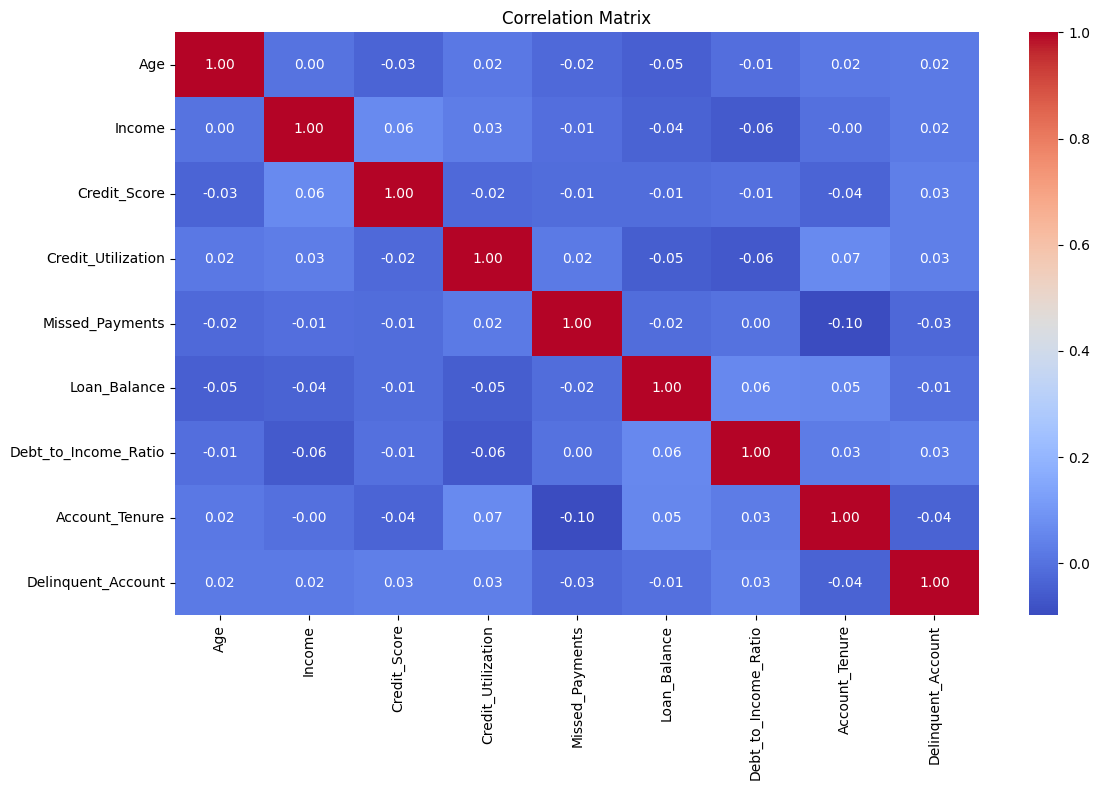

In [33]:
correlation = df_clean[
    risk_columns + ["Delinquent_Account"]
].corr(numeric_only=True)

# Correlation with target
target_correlation = correlation[
    "Delinquent_Account"
].sort_values(ascending=False)

print(target_correlation)

# Visualize correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

Interpretation:
- Positive correlation: Both variables tend to increase together.
- Negative correlation: One variable tends to decrease as the other increases.
- Near-zero correlation: Little linear relationship is observed.

Generate final data-quality and risk summary

In [34]:
# Missing values in original dataset
missing_summary = pd.DataFrame({
    "Original_Missing": df.isnull().sum()
})

# Number of imputed values
missing_summary["Imputed_Count"] = 0

missing_summary.loc["Income", "Imputed_Count"] = (
    df_clean["Income_Imputed"].sum()
)

missing_summary.loc["Loan_Balance", "Imputed_Count"] = (
    df_clean["Loan_Balance_Imputed"].sum()
)

missing_summary.loc["Credit_Score", "Imputed_Count"] = (
    df_clean["Credit_Score_Imputed"].sum()
)

print("MISSING VALUE SUMMARY")
print(missing_summary[missing_summary["Original_Missing"] > 0])

# Overall delinquency
total_customers = len(df_clean)

delinquent_customers = (
    df_clean["Delinquent_Account"].sum()
)

print("\nOVERALL DELINQUENCY")
print("Total Customers:", total_customers)
print("Delinquent Customers:", delinquent_customers)

print(
    "Delinquency Rate:",
    round(delinquent_customers / total_customers * 100, 2),
    "%"
)

# High-risk indicators to investigate
print("\nKEY RISK INDICATORS")

risk_indicators = [
    "Credit_Utilization",
    "Missed_Payments",
    "Debt_to_Income_Ratio",
    "Credit_Score",
    "Loan_Balance",
    "Account_Tenure"
]

for col in risk_indicators:

    correlation_value = df_clean[col].corr(
        df_clean["Delinquent_Account"]
    )

    print(
        col,
        "Correlation:",
        round(correlation_value, 3)
    )

print("\nANALYSIS COMPLETED")

MISSING VALUE SUMMARY
              Original_Missing  Imputed_Count
Income                      39             39
Credit_Score                 2              2
Loan_Balance                29             29

OVERALL DELINQUENCY
Total Customers: 500
Delinquent Customers: 80
Delinquency Rate: 16.0 %

KEY RISK INDICATORS
Credit_Utilization Correlation: 0.034
Missed_Payments Correlation: -0.026
Debt_to_Income_Ratio Correlation: 0.034
Credit_Score Correlation: 0.035
Loan_Balance Correlation: -0.005
Account_Tenure Correlation: -0.04

ANALYSIS COMPLETED


Save the cleaned dataset

In [35]:
# Save cleaned data into a new Excel file
df_clean.to_excel(
    "Delinquency_Prediction_Cleaned.xlsx",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


1. Key patterns and anomalies detected

- Credit utilization is slightly higher among delinquent customers, but the relationship is not consistently increasing across utilization groups.
- Customers with five missed payments have the highest observed delinquency rate, while customers with six missed payments have a lower rate.
- Unemployed customers have a higher delinquency rate than other employment groups.
- Business credit card customers show the highest delinquency rate among the card categories.
- Surprisingly, delinquent customers have slightly higher average credit scores and slightly fewer historical missed payments.
- The monthly payment history does not show a clear distinction between delinquent and non-delinquent customers.